> **Versão pública (2026).** Notebook original, executado no Google Colab com as bibliotecas e a chave da API do Kaggle numa pasta do Google Drive (`<PASTA_DO_PROJETO>`). As saídas são as originais; a pasta e a chave não fazem parte do repositório. Veja o [README](../README.md).

# Configuração de Ambiente

In [1]:
path_notebook = '/content/drive/MyDrive/<PASTA_DO_PROJETO>/'

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount = True)
#drive.flush_and_unmount()

Mounted at /content/drive


In [3]:
import os
import sys
path_minhaslibs = path_notebook + 'MinhasLibs/'
sys.path.insert(0, os.path.dirname(path_minhaslibs)) 

In [4]:
import AleTransforms as trf
import AleDatasetAnalysis as dat
import AleMLAnalysis as aml
import AleExplainers as exp
import AleLearners as lrn

In [5]:
import importlib
importlib.reload(trf)
importlib.reload(dat)
importlib.reload(aml)
importlib.reload(exp)
importlib.reload(lrn)

<module 'AleLearners' from '/content/drive/MyDrive/<PASTA_DO_PROJETO>/MinhasLibs/AleLearners.py'>

In [6]:
import pandas as pd
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from IPython.display import clear_output
from scipy.stats import pearsonr
import gc

In [7]:
import tensorflow as tf

# Acessa API do Kaggle e Baixa os Arquivos

In [8]:
#Instala a API
!pip install kaggle

In [9]:
# Move minhas credenciais para a pasta em que a API foi instalada
!mkdir -p ~/.kaggle/ && cp -i /content/drive/MyDrive/<PASTA_DO_PROJETO>/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

In [10]:
#Baixa dos dados do Projeto
!kaggle competitions download -c ubiquant-market-prediction

  0% 0.00/799k [00:00<?, ?B/s]
100% 799k/799k [00:00<00:00, 51.9MB/s]
  0% 0.00/59.0 [00:00<?, ?B/s]
100% 59.0/59.0 [00:00<00:00, 50.3kB/s]
100% 7.50G/7.50G [02:01<00:00, 69.5MB/s]
100% 7.50G/7.50G [02:01<00:00, 66.5MB/s]
  0% 0.00/52.6k [00:00<?, ?B/s]
100% 52.6k/52.6k [00:00<00:00, 47.1MB/s]
  0% 0.00/148 [00:00<?, ?B/s]
100% 148/148 [00:00<00:00, 146kB/s]


# Carrega a Base de Treino

In [11]:
df = pd.read_csv('train.csv.zip')

In [12]:
df

row_id  time_id  investment_id  ...     f_297     f_298     f_299
0              0_1        0              1  ... -1.044826 -0.287605  0.321566
1              0_2        0              2  ... -0.929529 -0.974060 -0.343624
2              0_6        0              6  ... -0.612428 -0.113944  0.243608
3              0_7        0              7  ... -0.783423  1.151730 -0.773309
4              0_8        0              8  ...  0.753279  1.345611 -0.737624
...            ...      ...            ...  ...       ...       ...       ...
3141405  1219_3768     1219           3768  ... -0.533092 -0.193732 -0.581394
3141406  1219_3769     1219           3769  ...  0.013145 -0.890270 -0.589705
3141407  1219_3770     1219           3770  ... -0.079106 -1.580124 -0.297625
3141408  1219_3772     1219           3772  ... -0.973762  0.608647 -0.372040
3141409  1219_3773     1219           3773  ... -0.563314  0.669586  0.456400

[3141410 rows x 304 columns]

# Conjuntos de Treino e Teste

In [13]:
time_ids = list(df['time_id'].value_counts().sort_index().index)

investment_ids = list(df['investment_id'].value_counts().index)
random.seed(42)
investment_ids = random.sample(investment_ids, len(investment_ids))

In [14]:
frac_teste_time = 0.1
frac_teste_investment = 0.1

In [15]:
time_ids_treino = time_ids[:int((1-frac_teste_time)*len(time_ids))]
time_ids_teste = time_ids[int((1-frac_teste_time)*len(time_ids)):]

investment_ids_treino = investment_ids[:int((1-frac_teste_investment)*len(investment_ids))]
investment_ids_teste = investment_ids[int((1-frac_teste_investment)*len(investment_ids)):]

In [16]:
mask_treino = (df['time_id'].isin(time_ids_treino) & df['investment_id'].isin(investment_ids_treino)).values

mask_teste_amostra = (df['time_id'].isin(time_ids_treino) & df['investment_id'].isin(investment_ids_teste)).values
mask_teste_tempo = (df['time_id'].isin(time_ids_teste) & df['investment_id'].isin(investment_ids_treino)).values

mask_teste = (df['time_id'].isin(time_ids_teste) & df['investment_id'].isin(investment_ids_teste)).values

In [17]:
print(np.sum(mask_treino)/df.shape[0])
print(np.sum(mask_teste_amostra)/df.shape[0])
print(np.sum(mask_teste_tempo)/df.shape[0])
print(np.sum(mask_teste)/df.shape[0])

0.7829777074625726
0.08843226449269595
0.11600268669164483
0.012587341353086671


In [18]:
print(set(time_ids_treino) & set(time_ids_teste))
print(set(investment_ids_treino) & set(investment_ids_teste))

set()
set()


# Conjuntos de Validação Cruzada

In [19]:
frac_val_time = 0.2
num_div = 4

frac_val_investment = 0.2
lista_seeds = [42, 7, 1, 12]

In [20]:
lista_time_ids_trainval = []

larg = int((1-frac_val_time)*len(time_ids_treino))
lista_ini = [int(i*(len(time_ids_treino) - larg)/num_div) for i in range(0, num_div)]
for ini in lista_ini[:-1]:
    fim = ini + larg
    time_ids_train = time_ids_treino[ini:fim]
    time_ids_val = list(np.append(time_ids_treino[:ini], time_ids_treino[fim:]))
    lista_time_ids_trainval.append((time_ids_train, time_ids_val))

ini = lista_ini[-1]
time_ids_train = time_ids_treino[ini:]
time_ids_val = time_ids_treino[:ini]
lista_time_ids_trainval.append((time_ids_train, time_ids_val))

In [21]:
lista_investiment_ids_trainval = []

for s in lista_seeds:
    random.seed(s)
    investment_ids_val = random.sample(investment_ids_treino, int(frac_val_investment*len(investment_ids_treino)))
    investment_ids_train = list(set(investment_ids_treino) - set(investment_ids_val))
    lista_investiment_ids_trainval.append((investment_ids_train, investment_ids_val))

In [22]:
lista_mask_trainval = []

for time_ids_trainval in lista_time_ids_trainval:
    for investiment_ids_trainval in lista_investiment_ids_trainval:
        mask_train = (df['time_id'].isin(time_ids_trainval[0]) & df['investment_id'].isin(investiment_ids_trainval[0])).values
        mask_val = (df['time_id'].isin(time_ids_trainval[1]) & df['investment_id'].isin(investiment_ids_trainval[1])).values
        lista_mask_trainval.append((mask_train, mask_val))

In [23]:
for time_ids_trainval in lista_time_ids_trainval:
    print(set(time_ids_trainval[0]) & set(time_ids_trainval[1]))

for investiment_ids_trainval in lista_investiment_ids_trainval:  
    print(set(investiment_ids_trainval[0]) & set(investiment_ids_trainval[1]))

set()
set()
set()
set()
set()
set()
set()
set()


In [24]:
len(lista_mask_trainval)

16

# Treinamento

In [25]:
colunas_id = ['row_id', 'time_id', 'investment_id']
alvo = 'target'

In [26]:
features = [f for f in df.columns if f not in colunas_id and f != alvo]

#### Features com Potencial de Overfitting

In [ ]:
def func(x):
    return (x[0].corr().iloc[0, 1], x[1].corr().iloc[0, 1])

lista_ret = []
for f in features:
    clear_output(wait = True)
    print(f)
    with Pool(os.cpu_count()) as p:
        ret = p.map(func, [(df.loc[mask_trainval[0], [alvo, f]], df.loc[mask_trainval[1], [alvo, f]]) for mask_trainval in lista_mask_trainval])
        lista_ret.append(ret)

joblib.dump(lista_ret, f'{path_notebook}ubiquant-market-prediction/correlacoes.pkl')

In [27]:
lista_ret = joblib.load(f'{path_notebook}ubiquant-market-prediction/correlacoes.pkl')
lista_df_corr = []
for i in range(0, len(features)):
    df_corr = pd.DataFrame(lista_ret[i], columns = ['corr_train', 'corr_val']).reset_index()
    df_corr['feature'] = features[i]
    df_corr = df_corr.rename({'index': 'conj'}, axis = 1)
    df_corr = df_corr[['feature', 'conj', 'corr_train', 'corr_val']]
    lista_df_corr.append(df_corr)
df_corr = pd.concat(lista_df_corr)

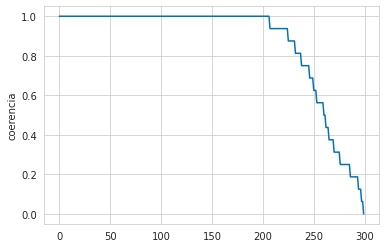

In [28]:
df_coer = df_corr.groupby('feature').apply(lambda x: pd.Series({'coerencia': np.mean(np.sign(x['corr_train']) == np.sign(x['corr_val']))}))
df_coer = df_coer.sort_values('coerencia', ascending = False).reset_index()

figsize = (6, 4)
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(1, 1, figsize = figsize)
    ax.plot(df_coer['coerencia'], color = paleta_cores[0])
    ax.set_ylabel('coerencia')
    plt.show()

In [29]:
features_sel = df_coer.loc[df_coer['coerencia'] == 1, 'feature']

### Treinamento - ML

In [30]:
medias = df[features_sel].mean()
desvios = df[features_sel].std()

In [31]:
media_y = df[alvo].mean()
desvio_y = df[alvo].std()

In [32]:
joblib.dump([features_sel, medias, desvios, media_y, desvio_y], f'{path_notebook}ubiquant-market-prediction/preprocessamento.pkl')

['/content/drive/MyDrive/<PASTA_DO_PROJETO>/ubiquant-market-prediction/preprocessamento.pkl']

In [33]:
features_sel, medias, desvios, media_y, desvio_y = joblib.load(f'{path_notebook}ubiquant-market-prediction/preprocessamento.pkl')

In [34]:
def cria_dict_avaliacao(H, std_train, std_val):
    d = {}
    d['melhor_iteracao'] = np.argmin(H.history['val_loss'])
    d['curva_treino'] = np.sqrt(H.history['loss'])
    d['curva_validacao'] = np.sqrt(H.history['val_loss'])
    d['desvio_treino'] = std_train
    d['desvio_validacao'] = std_val
    return d

def plot_curva_vies_variancia(aval):
    figsize = (6, 4)
    paleta_cores = sns.color_palette("colorblind")
    with sns.axes_style("whitegrid"):
        fig, ax = plt.subplots(1, 1, figsize = figsize)

        melhor_iter = aval['melhor_iteracao']
        curva_treino = np.array(aval['curva_treino'])/aval['desvio_treino']
        curva_validacao = np.array(aval['curva_validacao'])/aval['desvio_validacao']
        iteracoes = np.arange(0, curva_treino.size)
        ini = max(np.sum(curva_treino > 1), np.sum(curva_validacao > 1))
        if(ini == max(curva_treino.size, curva_validacao.size)):
            ini = 0

        ax.plot(iteracoes[ini:], curva_treino[ini:], color = paleta_cores[0], alpha = 1.0, label = 'Treino')
        ax.scatter(melhor_iter, curva_treino[melhor_iter], color = paleta_cores[0])
        ax.plot(iteracoes[ini:], curva_validacao[ini:], color = paleta_cores[1], alpha = 1.0, label = 'Validação')
        ax.scatter(melhor_iter, curva_validacao[melhor_iter], color = paleta_cores[1])
        ax.legend(bbox_to_anchor = (1.05, 1), loc = 'upper left')
        ax.set_xlabel('Iteração')
        ax.set_ylabel('RMSE Norm.')
        plt.show()

In [35]:
class CurvaViesVarianciaTreinamento(tf.keras.callbacks.Callback):
    
    def __init__(self, std_train, std_val):
        self.aval = {}
        self.aval['melhor_iteracao'] = 0
        self.aval['curva_treino'] = np.array([])
        self.aval['curva_validacao'] = np.array([])
        self.aval['desvio_treino'] = std_train
        self.aval['desvio_validacao'] = std_val
    
    def on_epoch_end(self, epoch, logs = {}):
        loss = logs.get('loss')
        val_loss = logs.get('val_loss')
        
        if(epoch > 0 and val_loss < np.min(self.aval['curva_validacao'])):
            self.aval['melhor_iteracao'] = epoch
        self.aval['curva_treino'] = np.append(self.aval['curva_treino'], loss)
        self.aval['curva_validacao'] = np.append(self.aval['curva_validacao'], val_loss)
        
        if epoch % 1 == 0:
            clear_output(wait = True)
            plot_curva_vies_variancia(self.aval)

In [46]:
def cria_rede():
    camada_entrada = tf.keras.layers.Input(shape = len(features_sel), name = 'entrada')
    lista_neuronios = [32, 16, 8, 4, 2]
    lista_dropout = list(np.repeat(0.0, len(lista_neuronios)))
    lista_camadas = [camada_entrada]
    for i in range(0, len(lista_neuronios)):
        n = lista_neuronios[i]
        lista_camadas.append(tf.keras.layers.Dense(n, activation = 'sigmoid', name = f'densa_{str(i)}')(lista_camadas[-1]))
        f = lista_dropout[i]
        if(f > 0):
            lista_camadas.append(tf.keras.layers.Dropout(f, name = f'drop_{str(i)}')(lista_camadas[-1]))
    camada_saida = tf.keras.layers.Dense(1, activation = 'linear', name = 'saida')(lista_camadas[-1])
    modelo = tf.keras.models.Model(inputs = camada_entrada, outputs = camada_saida, name = 'rgs')
    return modelo

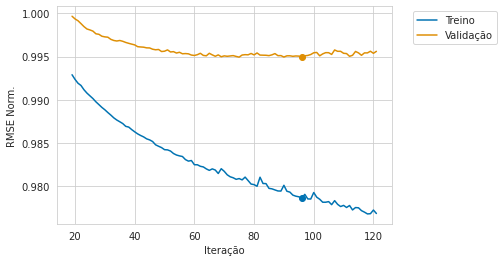

In [51]:
lista_rgs = []
lista_aval = []

for mask_trainval in lista_mask_trainval:
    mask_train = mask_trainval[0]
    mask_val = mask_trainval[1]

    gc.collect()

    rgs = cria_rede()
    opt = tf.keras.optimizers.Adam(learning_rate = 0.001)
    func_loss = tf.keras.losses.MeanSquaredError()
    rgs.compile(loss = func_loss, optimizer = opt)

    callback = tf.keras.callbacks.EarlyStopping(
                                                monitor = 'val_loss', 
                                                min_delta = 0, 
                                                patience = 25, 
                                                verbose = 0,
                                                mode = 'auto', 
                                                restore_best_weights = True
                                                )
    
    std_train = df.loc[mask_train, alvo].std()/desvio_y
    std_val = df.loc[mask_val, alvo].std()/desvio_y
    callback_plot = CurvaViesVarianciaTreinamento(std_train, std_val)

    n_batchs = 64
    H = rgs.fit((df.loc[mask_train, features_sel] - medias)/desvios, (df.loc[mask_train, alvo] - media_y)/desvio_y,
                validation_data = ((df.loc[mask_val, features_sel] - medias)/desvios, (df.loc[mask_val, alvo] - media_y)/desvio_y),
                epochs = 500,
                batch_size = int(np.sum(np.sum(mask_train))/n_batchs), 
                callbacks = [callback, callback_plot],
                verbose = False)
    
    lista_rgs.append(rgs)

    aval = cria_dict_avaliacao(H, std_train, std_val)
    lista_aval.append(aval)

    #plot_curva_vies_variancia(aval)

In [52]:
joblib.dump(lista_aval, f'{path_notebook}ubiquant-market-prediction/rnn_avaliacoes.pkl')

i = 0
for rgs in lista_rgs:
    rgs.save(f'{path_notebook}ubiquant-market-prediction/rnn_{str(i)}.h5')
    i = i + 1

In [53]:
lista_aval = joblib.load(f'{path_notebook}ubiquant-market-prediction/rnn_avaliacoes.pkl')

i = 0
lista_rgs = []
for i in range(0, len(lista_mask_trainval)):
    rgs = cria_rede()
    rgs = tf.keras.models.load_model(f'{path_notebook}ubiquant-market-prediction/rnn_{str(i)}.h5')
    lista_rgs.append(rgs)
    i = i + 1

In [54]:
class EnsembleRegressor():

    def __init__(self, lista_rgs, medias, desvios, media_y, desvio_y, features):
        self.lista_rgs = lista_rgs
        self.medias = medias
        self.desvios = desvios
        self.media_y = media_y
        self.desvio_y = desvio_y
        self.feature_names_ = features
    
    def predict(self, X):
        return self.media_y + self.desvio_y*np.mean(np.array([rgs.predict((X[self.feature_names_] - self.medias)/self.desvios) for rgs in self.lista_rgs]), axis = 0)

In [64]:
rgs_ens = EnsembleRegressor(lista_rgs, medias, desvios, media_y, desvio_y, features_sel)

In [56]:
iteracao_cv = int(round(np.mean([aval['melhor_iteracao'] for aval in lista_aval]), 0))
print(iteracao_cv)

rgs = cria_rede()
opt = tf.keras.optimizers.Adam(learning_rate = 0.001)
func_loss = tf.keras.losses.MeanSquaredError()
rgs.compile(loss = func_loss, optimizer = opt)

n_batchs = 64
H = rgs.fit((df.loc[mask_treino, features_sel] - medias)/desvios, (df.loc[mask_treino, alvo] - media_y)/desvio_y,
                epochs = iteracao_cv,
                batch_size = int(np.sum(np.sum(mask_treino))/n_batchs), 
                verbose = False)

75


In [57]:
rgs.save(f'{path_notebook}ubiquant-market-prediction/rnn_cv.h5')

In [58]:
rgs = cria_rede()
rgs = tf.keras.models.load_model(f'{path_notebook}ubiquant-market-prediction/rnn_cv.h5')

In [65]:
rgs_c = EnsembleRegressor([rgs], medias, desvios, media_y, desvio_y, features_sel)

# Avaliação

In [59]:
df_aval = df[['row_id', 'time_id', 'investment_id', 'target']].copy()

In [60]:
df_aval['conj'] = np.nan

df_aval.loc[mask_treino, 'conj'] = 'Treino'
df_aval.loc[mask_teste_amostra, 'conj'] = 'Teste_Amostra'
df_aval.loc[mask_teste_tempo, 'conj'] = 'Teste_Tempo'
df_aval.loc[mask_teste, 'conj'] = 'Teste'

In [61]:
def predict_batch(df, rgs, mask, particoes = 100):
    features = rgs.feature_names_
    mask_splits = np.array_split(mask.nonzero()[0], particoes)
    lista_pred = []
    i = 0
    for inds in mask_splits:
        clear_output(wait = True)
        print(f'{str(i)} / {str(particoes)}')
        i = i + 1
        lista_pred.append(rgs.predict(df.iloc[inds][features]))
    return np.concatenate(lista_pred)

In [68]:
df_aval['pred'] = np.nan

rgs_aval = rgs_c #rgs_ens
particoes = 10

df_aval.loc[mask_treino, 'pred'] = predict_batch(df, rgs_aval, mask_treino, particoes = particoes)
df_aval.loc[mask_teste_amostra, 'pred'] = predict_batch(df, rgs_aval, mask_teste_amostra, particoes = particoes)
df_aval.loc[mask_teste_tempo, 'pred'] = predict_batch(df, rgs_aval, mask_teste_tempo, particoes = particoes)
df_aval.loc[mask_teste, 'pred'] = predict_batch(df, rgs_aval, mask_teste, particoes = particoes)

9 / 10


In [69]:
def metricas(x):
    d = {}
    d['correlacao_media'] = np.mean(x.groupby('time_id').apply(lambda y: pd.Series({'correlacao': pearsonr(y[alvo], y['pred'])[0]}))['correlacao'])
    return pd.Series(d)

In [70]:
df_aval.groupby('conj').apply(lambda x: metricas(x))

correlacao_media
conj                           
Teste                  0.084683
Teste_Amostra          0.134125
Teste_Tempo            0.093944
Treino                 0.138813